# Adjusted return check

Visual verification of the generic return construction used by the backtester. Run from the `notebooks/` folder after `python -m data.download`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from backtest.returns import build_instrument_returns, prepare_backtest_data

COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "green": "#3f8f5b",
          "ink": "#0b0b0b", "muted": "#898781", "grid": "#e1e0d9"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["grid"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": COLORS["muted"],
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "text.color": COLORS["ink"], "axes.titlecolor": COLORS["ink"],
})

df = pd.read_parquet(Path("../data/cache/spy_dataset.parquet"))
returns = build_instrument_returns(df)
print(df.shape, df.index[0].date(), "->", df.index[-1].date())

(6661, 11) 2000-01-04 -> 2026-06-30


## Adjusted prices

The dataset stores raw open and close plus adjusted close. The backtester applies the daily close adjustment factor to the raw open so both prices share one scale.

In [2]:
adjustment_factor = df["adj_close"] / df["close"]
adjusted_open = df["open"] * adjustment_factor
pd.DataFrame({
    "raw_open": df["open"],
    "raw_close": df["close"],
    "adjusted_open": adjusted_open,
    "adjusted_close": df["adj_close"],
}).head()

,raw_open,raw_close,adjusted_open,adjusted_close
date,,,,
2000-01-04,143.53125,139.75,89.938243,87.568871
2000-01-05,139.93750,140.00,87.686407,87.725571
2000-01-06,139.62500,137.75,87.490531,86.315636
2000-01-07,140.31250,145.75,87.921384,91.328583
2000-01-10,146.25000,146.25,91.641891,91.641891


## Close-to-close consistency

The reconstructed close-to-close return must equal the `ret` column produced by the data pipeline.

In [3]:
close_to_close = returns["return_close_to_close"]
difference = (close_to_close - df["ret"]).abs().dropna()
assert difference.max() < 1e-15
print(f"maximum difference against dataset ret: {difference.max():.3e}")

maximum difference against dataset ret: 0.000e+00


## Overnight and intraday decomposition

Compounding the overnight and intraday legs must recover the adjusted close-to-close return on every date.

In [4]:
composed = (1 + returns["return_overnight"]) * (1 + returns["return_intraday"]) - 1
error = (composed - returns["return_close_to_close"]).abs().dropna()
assert error.max() < 1e-12
print(f"maximum decomposition error: {error.max():.3e}")

maximum decomposition error: 2.220e-16


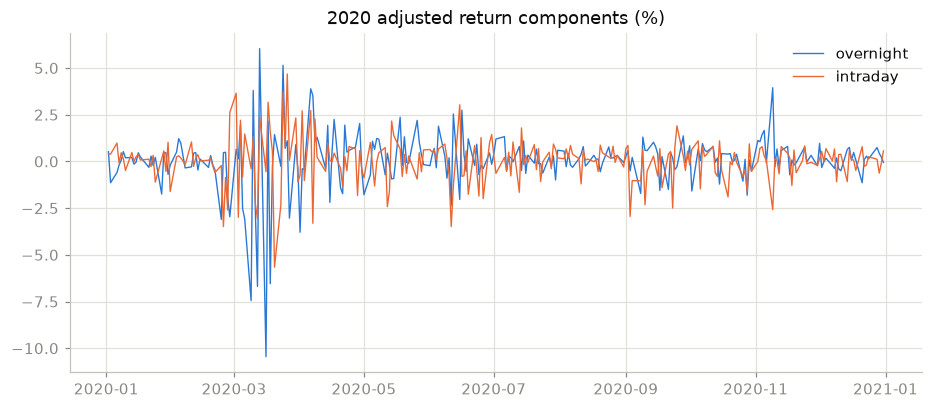

In [5]:
zoom = returns.loc["2020"] * 100
fig, ax = plt.subplots()
ax.plot(zoom.index, zoom["return_overnight"], lw=0.9,
        color=COLORS["blue"], label="overnight")
ax.plot(zoom.index, zoom["return_intraday"], lw=0.9,
        color=COLORS["orange"], label="intraday")
ax.set_title("2020 adjusted return components (%)")
ax.legend(frameon=False)
plt.show()

## First out-of-sample date

Returns are built before selecting forecast dates, so the first out-of-sample row keeps the previous in-sample close.

In [6]:
oos_index = df.loc["2010-01-01":].index
synthetic_forecasts = pd.Series(0.01, index=oos_index, name="forecast")
prepared = prepare_backtest_data(df, synthetic_forecasts)
first = oos_index[0]
assert prepared.loc[first, "return_close_to_close"] == df.loc[first, "ret"]
prepared.head()

,forecast_vol,rf,return_close_to_close,return_overnight,return_intraday
date,,,,,
2010-01-04,0.01,0.000002,0.016960,0.008345,0.008543
2010-01-05,0.01,0.000003,0.002647,-0.000618,0.003267
2010-01-06,0.01,0.000003,0.000704,-0.000968,0.001674
2010-01-07,0.01,0.000002,0.004221,-0.001847,0.006079
2010-01-08,0.01,0.000002,0.003328,-0.002627,0.005971


## Largest component moves

The largest absolute overnight and intraday returns provide a final date-level audit of the decomposition.

In [7]:
overnight_audit = returns["return_overnight"].abs().nlargest(5).to_frame()
intraday_audit = returns["return_intraday"].abs().nlargest(5).to_frame()
display(overnight_audit.style.format("{:.2%}").set_caption("Overnight"))
display(intraday_audit.style.format("{:.2%}").set_caption("Intraday"))

,return_overnight
date,
2020-03-16 00:00:00,10.45%
2008-10-24 00:00:00,8.32%
2001-09-17 00:00:00,8.22%
2020-03-09 00:00:00,7.45%
2020-03-12 00:00:00,6.69%


,return_intraday
date,
2025-04-09 00:00:00,11.18%
2008-10-09 00:00:00,8.99%
2002-07-24 00:00:00,8.43%
2008-10-13 00:00:00,7.97%
2008-10-15 00:00:00,7.63%
